In [ ]:
import torch
from torch import nn
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


In [ ]:
import os

os.environ['KAGGLE_API_TOKEN'] = 'KAGGLE_API_TOKEN'

In [ ]:
!pip install -q kaggle

In [ ]:
!kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset

Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
brain-tumor-mri-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
!mkdir -p ~/.kaggle
!echo "KAGGLE_API_TOKEN" > ~/.kaggle/access_token
!chmod 600 ~/.kaggle/access_token

In [ ]:
!kaggle competitions list

ref                                                                           deadline             category         reward  teamCount  userHasEntered  
----------------------------------------------------------------------------  -------------------  --------  -------------  ---------  --------------  
https://www.kaggle.com/competitions/passenger-screening-algorithm-challenge   2017-12-15 23:59:00  Featured  1,500,000 Usd        518           False  
https://www.kaggle.com/competitions/zillow-prize-1                            2018-01-10 15:59:00  Featured  1,200,000 Usd       3770           False  
https://www.kaggle.com/competitions/data-science-bowl-2017                    2017-04-12 23:59:00  Featured  1,000,000 Usd       1972           False  
https://www.kaggle.com/competitions/vesuvius-challenge-ink-detection          2023-06-14 23:59:00  Featured  1,000,000 Usd       1249           False  
https://www.kaggle.com/competitions/arc-prize-2026-arc-agi-3                  2026-11-02

In [ ]:
!unzip brain-tumor-mri-dataset.zip

Archive:  brain-tumor-mri-dataset.zip
replace Testing/glioma/Te-gl_1.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
data_transforms = {
    "Training" : transforms.Compose([
        transforms.Resize((224,224)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(10),
        transforms.ToTensor(),
        transforms.Normalize([0.5] , [0.5])
    ]),

    "Testing" : transforms.Compose([
        transforms.Resize((224,224)),
        transforms.ToTensor(),
        transforms.Normalize([0.5] , [0.5])
    ])
}

In [ ]:
image_datasets = {
    "Training" : datasets.ImageFolder("Training" , data_transforms["Training"]),
    "Testing" : datasets.ImageFolder("Testing" , data_transforms["Testing"])
}

In [ ]:
data_loaders = {
    "Training" : DataLoader(image_datasets["Training"] , batch_size=32 , shuffle=True , num_workers=2 , pin_memory=True),
    "Testing" : DataLoader(image_datasets["Testing"] , batch_size=32 , shuffle=False , num_workers=2 , pin_memory=True)
}

In [ ]:
import torch
import torch.nn as nn

class BrainMRIModel(nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()

        # Block 1
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(input_shape, hidden_units, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(hidden_units),
            nn.ReLU(),

            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(hidden_units),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Block 2
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(hidden_units, hidden_units*2, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(hidden_units*2),
            nn.ReLU(),

            nn.Conv2d(hidden_units*2, hidden_units*2, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(hidden_units*2),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Block 3
        self.conv_block_3 = nn.Sequential(
            nn.Conv2d(hidden_units*2, hidden_units*4, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(hidden_units*4),
            nn.ReLU(),

            nn.Conv2d(hidden_units*4, hidden_units*4, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(hidden_units*4),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(p=0.5),
            nn.Linear(hidden_units*4, hidden_units*2),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(hidden_units*2, output_shape)
        )

    def forward(self, x: torch.Tensor):
        x = self.conv_block_1(x)
        x = self.conv_block_2(x)
        x = self.conv_block_3(x)
        x = self.classifier(x)
        return x

In [ ]:
model = BrainMRIModel(3 , 16 , 4)
model.to(device)

BrainMRIModel(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_3): Sequential(


In [ ]:
model.eval()

BrainMRIModel(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_3): Sequential(


In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params = model.parameters() , lr = 0.001 , weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=2,
)

In [ ]:
import torch

Epochs = 20

print("🚀 Training started")

for epoch in range(Epochs):

    print(f"\n🔥 Starting Epoch {epoch+1}")

    # ---------------- TRAIN ----------------
    print("➡️ Entering train mode")
    model.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    print("⏳ Starting training loop...")

    for i, (X, y) in enumerate(data_loaders["Training"]):

        if i == 0:
            print("✅ First training batch loaded")

        X = X.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True).long()

        optimizer.zero_grad()

        y_logits = model(X)
        loss = loss_fn(y_logits, y)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

        preds = torch.argmax(y_logits, dim=1)
        train_correct += (preds == y).sum().item()
        train_total += y.size(0)

    print("✅ Training loop finished")

    train_loss /= len(data_loaders["Training"])
    train_acc = 100 * train_correct / train_total

    # ---------------- TEST ----------------
    print("➡️ Entering eval mode")
    model.eval()

    test_loss = 0
    correct = 0
    total = 0

    print("⏳ Starting test loop...")

    with torch.inference_mode():

        for i, (X, y) in enumerate(data_loaders["Testing"]):

            if i == 0:
                print("✅ First test batch loaded")

            X = X.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True).long()

            y_logits = model(X)
            loss = loss_fn(y_logits, y)

            test_loss += loss.item()

            preds = torch.argmax(y_logits, dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)

    print("✅ Test loop finished")

    test_loss /= len(data_loaders["Testing"])
    test_acc = 100 * correct / total

    print(f"\n📊 Epoch {epoch+1}/{Epochs} DONE")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
    print(f"Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.2f}%")

    scheduler.step(test_loss)

🚀 Training started

🔥 Starting Epoch 1
➡️ Entering train mode
⏳ Starting training loop...
✅ First training batch loaded
✅ Training loop finished
➡️ Entering eval mode
⏳ Starting test loop...
✅ First test batch loaded
✅ Test loop finished

📊 Epoch 1/20 DONE
Train Loss: 1.0031 | Train Acc: 58.46%
Test Loss: 1.4419 | Test Acc: 43.38%

🔥 Starting Epoch 2
➡️ Entering train mode
⏳ Starting training loop...
✅ First training batch loaded
✅ Training loop finished
➡️ Entering eval mode
⏳ Starting test loop...
✅ First test batch loaded
✅ Test loop finished

📊 Epoch 2/20 DONE
Train Loss: 0.8193 | Train Acc: 67.34%
Test Loss: 1.1694 | Test Acc: 52.19%

🔥 Starting Epoch 3
➡️ Entering train mode
⏳ Starting training loop...
✅ First training batch loaded
✅ Training loop finished
➡️ Entering eval mode
⏳ Starting test loop...
✅ First test batch loaded
✅ Test loop finished

📊 Epoch 3/20 DONE
Train Loss: 0.7344 | Train Acc: 71.46%
Test Loss: 1.6454 | Test Acc: 48.38%

🔥 Starting Epoch 4
➡️ Entering train m

In [ ]:
import torchvision.models as models

model_resnet18 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
num_ftrs = model_resnet18.fc.in_features

model_resnet18.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(num_ftrs, 4)
)

model_resnet18 = model_resnet18.to(device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 189MB/s]


In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params = model_resnet18.parameters() , lr = 0.001 , weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=2,
)

In [ ]:
model_resnet18.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [ ]:
import torch

Epochs = 15

best_test_loss = float('inf')

print("🚀 Training started")

for epoch in range(Epochs):

    print(f"\n🔥 Starting Epoch {epoch+1}")

    # ---------------- TRAIN ----------------
    print("➡️ Entering train mode")
    model_resnet18.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    print("⏳ Starting training loop...")

    for i, (X, y) in enumerate(data_loaders["Training"]):
        X = X.to(device)
        y = y.to(device).long()

        optimizer.zero_grad()

        # Use model_2 instead of model
        y_logits = model_resnet18(X)
        loss = loss_fn(y_logits, y)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

        preds = torch.argmax(y_logits, dim=1)
        train_correct += (preds == y).sum().item()
        train_total += y.size(0)

    train_loss /= len(data_loaders["Training"])
    train_acc = 100 * train_correct / train_total

    # ---------------- TEST ----------------
    print("➡️ Entering eval mode")
    model_resnet18.eval()

    test_loss = 0
    correct = 0
    total = 0

    with torch.inference_mode():
        for X, y in data_loaders["Testing"]:
            X = X.to(device)
            y = y.to(device).long()

            y_logits = model_resnet18(X)
            loss = loss_fn(y_logits, y)

            test_loss += loss.item()

            preds = torch.argmax(y_logits, dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)

    test_loss /= len(data_loaders["Testing"])
    test_acc = 100 * correct / total

    print(f"\n📊 Epoch {epoch+1}/{Epochs} DONE")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
    print(f"Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.2f}%")

    if test_loss < best_test_loss:
        best_test_loss = test_loss
        print(f"💾 New best model found! Saving weights to 'best_model.pth'...")
        torch.save(model_resnet18.state_dict(), "best_model.pth")

    scheduler.step(test_loss)

🚀 Training started

🔥 Starting Epoch 1
➡️ Entering train mode
⏳ Starting training loop...
➡️ Entering eval mode

📊 Epoch 1/15 DONE
Train Loss: 0.3547 | Train Acc: 87.05%
Test Loss: 0.5742 | Test Acc: 85.00%
💾 New best model found! Saving weights to 'best_model.pth'...

🔥 Starting Epoch 2
➡️ Entering train mode
⏳ Starting training loop...
➡️ Entering eval mode

📊 Epoch 2/15 DONE
Train Loss: 0.1946 | Train Acc: 93.25%
Test Loss: 0.4141 | Test Acc: 92.31%
💾 New best model found! Saving weights to 'best_model.pth'...

🔥 Starting Epoch 3
➡️ Entering train mode
⏳ Starting training loop...
➡️ Entering eval mode

📊 Epoch 3/15 DONE
Train Loss: 0.1535 | Train Acc: 94.57%
Test Loss: 0.4287 | Test Acc: 89.88%

🔥 Starting Epoch 4
➡️ Entering train mode
⏳ Starting training loop...
➡️ Entering eval mode

📊 Epoch 4/15 DONE
Train Loss: 0.1157 | Train Acc: 95.91%
Test Loss: 0.4296 | Test Acc: 90.38%

🔥 Starting Epoch 5
➡️ Entering train mode
⏳ Starting training loop...
➡️ Entering eval mode

📊 Epoch 5/1

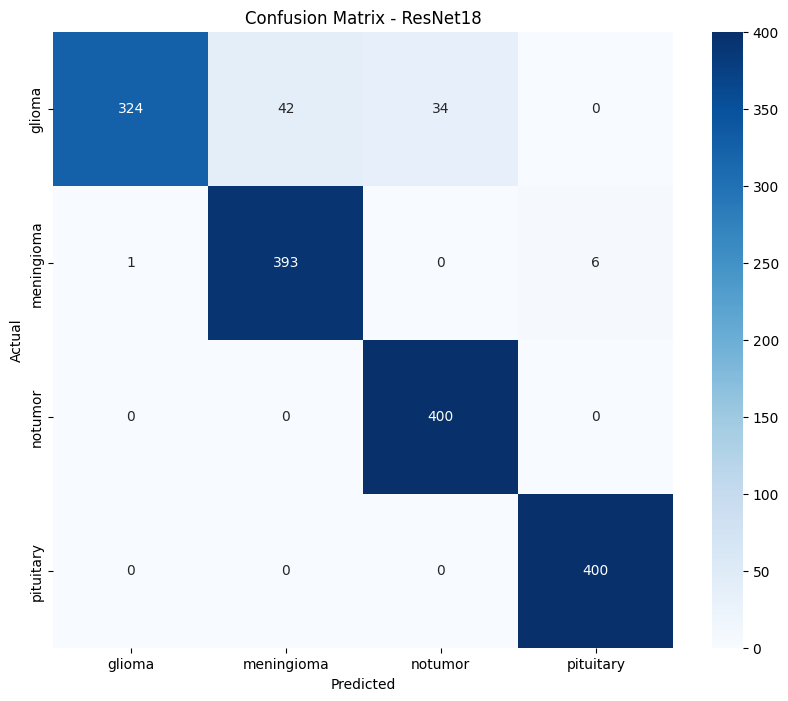

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

all_preds = []
all_labels = []

model_resnet18.eval()
with torch.inference_mode():
    for X, y in data_loaders['Testing']:
        X, y = X.to(device), y.to(device)
        outputs = model_resnet18(X)
        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y.cpu().numpy())

class_names = image_datasets['Testing'].classes
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - ResNet18')
plt.show()

🔍 Analyzing test set predictions...


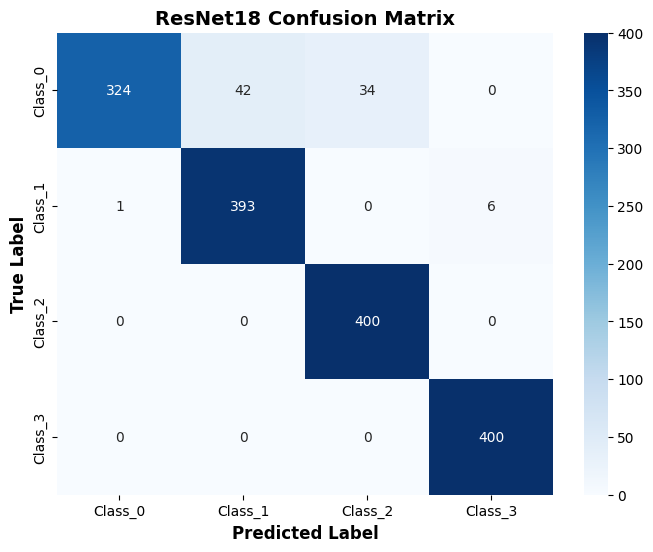

In [ ]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

model_resnet18.eval()

all_preds = []
all_labels = []

print("🔍 Analyzing test set predictions...")

with torch.inference_mode():
    for X, y in data_loaders["Testing"]:
        X = X.to(device)
        y = y.to(device)

        y_logits = model_resnet18(X)
        preds = torch.argmax(y_logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y.cpu().numpy())

class_names = ["Class_0", "Class_1", "Class_2", "Class_3"]

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)

plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
plt.ylabel('True Label', fontsize=12, fontweight='bold')
plt.title('ResNet18 Confusion Matrix', fontsize=14, fontweight='bold')
plt.show()